In [85]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split , cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, LabelBinarizer
from sklearn.metrics import classification_report , roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay, log_loss

In [86]:
df = pd.read_csv("new_Iris.csv") 
df.head(3)
df.drop(columns=["Unnamed: 0"],axis=1,inplace=True)
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,SepalLengthRatio,PetalLengthRatio,SepalElipseAreaCm2,PetalElipseAreaCm2
0,5.1,3.5,1.4,0.2,Iris-setosa,1.457143,7.0,14.019357,1.539380
1,4.9,3.0,1.4,0.2,Iris-setosa,1.633333,7.0,11.545353,1.539380
2,4.7,3.2,1.3,0.2,Iris-setosa,1.468750,6.5,11.812388,1.327323
3,4.6,3.1,1.5,0.2,Iris-setosa,1.483871,7.5,11.199778,1.767146
4,5.0,3.6,1.4,0.2,Iris-setosa,1.388889,7.0,14.137167,1.539380


In [87]:
X = df.drop(columns=["Species"],axis=1) 
Y = df.Species 

In [88]:
le = LabelEncoder() 
df.Species = le.fit_transform(df.Species)  
df

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,SepalLengthRatio,PetalLengthRatio,SepalElipseAreaCm2,PetalElipseAreaCm2
0,5.1,3.5,1.4,0.2,0,1.457143,7.000000,14.019357,1.539380
1,4.9,3.0,1.4,0.2,0,1.633333,7.000000,11.545353,1.539380
2,4.7,3.2,1.3,0.2,0,1.468750,6.500000,11.812388,1.327323
3,4.6,3.1,1.5,0.2,0,1.483871,7.500000,11.199778,1.767146
4,5.0,3.6,1.4,0.2,0,1.388889,7.000000,14.137167,1.539380
...,...,...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,2.233333,2.260870,15.786503,21.237166
146,6.3,2.5,5.0,1.9,2,2.520000,2.631579,12.370021,19.634954
147,6.5,3.0,5.2,2.0,2,2.166667,2.600000,15.315264,21.237166
148,6.2,3.4,5.4,2.3,2,1.823529,2.347826,16.556193,22.902210


In [89]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.3,random_state=42) 

sc = StandardScaler() 
x_train_sc = sc.fit_transform(X_train) 
x_test_sc = sc.transform(X_test) 

Model Test Skoru: 1.0
Model Eğitim Skoru: 0.97143
Model Log Loss Oranı: 0.08989

Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: [0.95238095 0.9047619  0.95238095 1.         0.9047619 ]
Ortalama Skor: 0.94286
Skorların Standart Sapması: 0.03563

ROC-AUC Skoru: 1.00

Logistic Regression Sınıflandırma Raporu
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        19
Iris-versicolor       1.00      1.00      1.00        13
 Iris-virginica       1.00      1.00      1.00        13

       accuracy                           1.00        45
      macro avg       1.00      1.00      1.00        45
   weighted avg       1.00      1.00      1.00        45



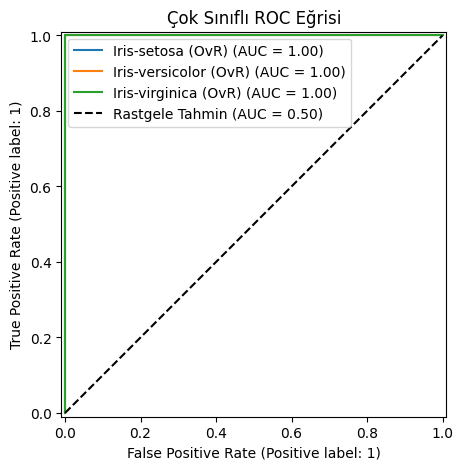

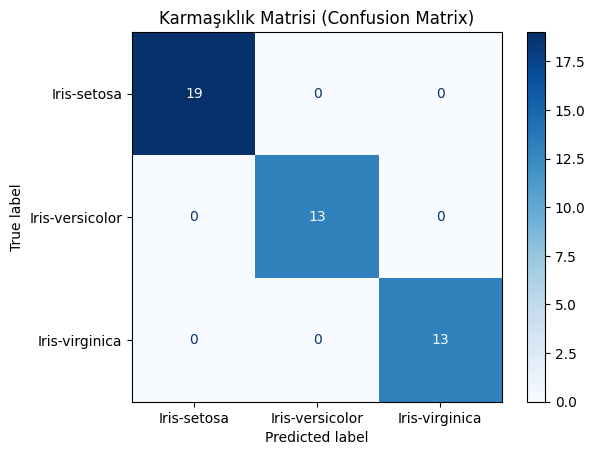

In [91]:
from sklearn.linear_model import LogisticRegression 

logr = LogisticRegression() 

logr.fit(x_train_sc,Y_train) 

logr_predict = logr.predict(x_test_sc) 
logr_pred_prob = logr.predict_proba(x_test_sc) 

logr_score = logr.score(x_test_sc,Y_test) 
logr_train_score = logr.score(x_train_sc,Y_train)

logr_cv_score = cross_val_score(logr,x_train_sc,Y_train,cv=5)

logr_log_loss = log_loss(Y_test,logr_pred_prob)

logr_roc_auc = roc_auc_score(Y_test, logr_pred_prob, multi_class='ovr')

print(f"Model Test Skoru: {logr_score}") 
print(f"Model Eğitim Skoru: {logr_train_score:.5f}") 
print(f"Model Log Loss Oranı: {logr_log_loss:.5f}") 
print(f"""
Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: {logr_cv_score}
Ortalama Skor: {logr_cv_score.mean():.5f}
Skorların Standart Sapması: {logr_cv_score.std():.5f}
""") 
print(f"ROC-AUC Skoru: {logr_roc_auc:.2f}\n")

print("Logistic Regression Sınıflandırma Raporu\n",classification_report(Y_test,logr_predict)) 

lb = LabelBinarizer().fit(Y_train) 
y_test_bin = lb.transform(Y_test) 

(fig,ax) = plt.subplots(figsize=(7,5)) 

for i,classname in enumerate(lb.classes_): 
    RocCurveDisplay.from_predictions(
        y_test_bin[:,i],
        logr_pred_prob[:,i],
        name=f"{classname} (OvR)",
        ax=ax
    )

plt.plot([0, 1], [0, 1], "k--", label="Rastgele Tahmin (AUC = 0.50)")
plt.title("Çok Sınıflı ROC Eğrisi")
plt.legend()
plt.show()

cm = confusion_matrix(Y_test, logr_predict)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logr.classes_)
disp.plot(cmap="Blues")
plt.title("Karmaşıklık Matrisi (Confusion Matrix)")
plt.show()